# ***IMPORT of used Liberaries***

In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from sklearn.metrics import roc_curve, roc_auc_score

# ***Understanding Data (EDA) and cleaning data***

In [2]:
df = pd.read_csv("/content/spam_ham_dataset.csv", encoding="latin-1", on_bad_lines="skip")
df.head()

,Unnamed: 0,label,text,label_num
0,605,ham,Subject: enron methanol ; meter # : 988291\r\n...,0
1,2349,ham,"Subject: hpl nom for january 9 , 2001\r\n( see...",0
2,3624,ham,"Subject: neon retreat\r\nho ho ho , we ' re ar...",0
3,4685,spam,"Subject: photoshop , windows , office . cheap ...",1
4,2030,ham,Subject: re : indian springs\r\nthis deal is t...,0


In [3]:
df.tail()

,Unnamed: 0,label,text,label_num
5166,1518,ham,Subject: put the 10 on the ft\r\nthe transport...,0
5167,404,ham,Subject: 3 / 4 / 2000 and following noms\r\nhp...,0
5168,2933,ham,Subject: calpine daily gas nomination\r\n>\r\n...,0
5169,1409,ham,Subject: industrial worksheets for august 2000...,0
5170,4807,spam,Subject: important online banking alert\r\ndea...,1


In [4]:
df.shape

(5171, 4)

In [5]:
df.dtypes

,0
Unnamed: 0,int64
label,object
text,object
label_num,int64


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5171 entries, 0 to 5170
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Unnamed: 0  5171 non-null   int64 
 1   label       5171 non-null   object
 2   text        5171 non-null   object
 3   label_num   5171 non-null   int64 
dtypes: int64(2), object(2)
memory usage: 161.7+ KB


In [7]:
df.describe(include="all")

,Unnamed: 0,label,text,label_num
count,5171.000000,5171,5171,5171.000000
unique,NaN,2,4993,NaN
top,NaN,ham,Subject: calpine daily gas nomination\r\n>\r\n...,NaN
freq,NaN,3672,20,NaN
mean,2585.000000,NaN,NaN,0.289886
std,1492.883452,NaN,NaN,0.453753
min,0.000000,NaN,NaN,0.000000
25%,1292.500000,NaN,NaN,0.000000
50%,2585.000000,NaN,NaN,0.000000
75%,3877.500000,NaN,NaN,1.000000


In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df[df.duplicated()]


,Unnamed: 0,label,text,label_num


In [10]:
df.duplicated(subset=['text']).sum()

np.int64(178)

In [11]:
df.drop_duplicates(subset=['text'], inplace=True)

In [12]:
print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (4993, 4)


In [13]:
df.isnull().sum()

,0
Unnamed: 0,0
label,0
text,0
label_num,0


In [14]:
(df['text'].str.strip() == '').sum()

np.int64(0)

In [15]:
df['label'].value_counts()

,count
label,
ham,3531
spam,1462


In [16]:
df['label'].value_counts(normalize=True) * 100

,proportion
label,
ham,70.719007
spam,29.280993


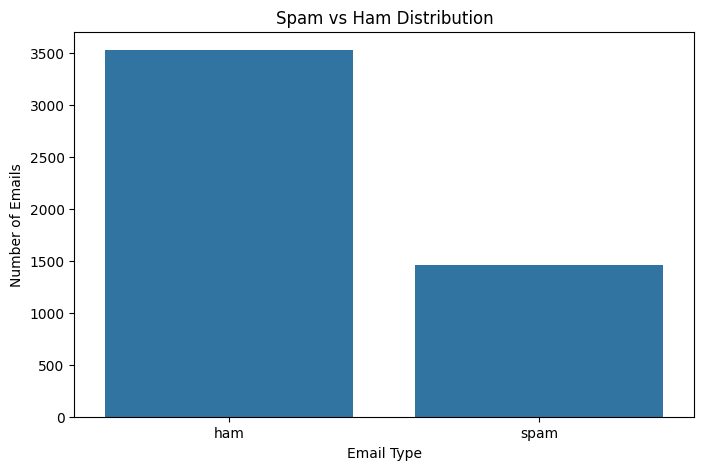

In [18]:


plt.figure(figsize=(8,5))

sns.countplot(data=df, x='label')

plt.title('Spam vs Ham Distribution')
plt.xlabel('Email Type')
plt.ylabel('Number of Emails')

plt.show()

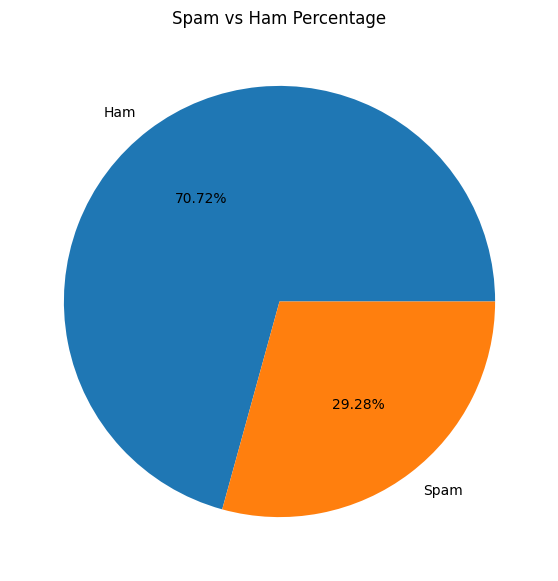

In [19]:
df['label'].value_counts().plot(
    kind='pie',
    autopct='%1.2f%%',
    figsize=(7,7),
    labels=['Ham', 'Spam']
)

plt.title('Spam vs Ham Percentage')
plt.ylabel('')

plt.show()

In [20]:
pd.crosstab(df['label'], df['label_num'])

label_num,0,1
label,,
ham,3531,0
spam,0,1462


In [ ]:
df.to_csv('/content/cleaned_spam.csv', index=False)

# ***Text preprocessing***

In [22]:
def clean_text(text):
    text = text.lower()

    text = re.sub(r'<[^>]+>', ' ', text)

    text = re.sub(r'https?://\S+|www\.\S+', ' urltoken ', text)

    text = re.sub(r'\b[\w.-]+@[\w.-]+\.\w+\b', ' emailtoken ', text)

    text = re.sub(r'[$£€]', ' currencytoken ', text)


    text = text.replace('!', ' exclamationtoken ')


    text = re.sub(r'[^a-z0-9\s]', ' ', text)

    text = re.sub(r'\s+', ' ', text).strip()

    return text


df['clean_text'] = df['text'].apply(clean_text)

display(df[['text', 'clean_text']].head(10))

,text,clean_text
0,Subject: enron methanol ; meter # : 988291\r\n...,subject enron methanol meter 988291 this is a ...
1,"Subject: hpl nom for january 9 , 2001\r\n( see...",subject hpl nom for january 9 2001 see attache...
2,"Subject: neon retreat\r\nho ho ho , we ' re ar...",subject neon retreat ho ho ho we re around to ...
3,"Subject: photoshop , windows , office . cheap ...",subject photoshop windows office cheap main tr...
4,Subject: re : indian springs\r\nthis deal is t...,subject re indian springs this deal is to book...
5,Subject: ehronline web address change\r\nthis ...,subject ehronline web address change this mess...
6,Subject: spring savings certificate - take 30 ...,subject spring savings certificate take 30 off...
7,Subject: looking for medication ? we ` re the ...,subject looking for medication we re the best ...
8,Subject: noms / actual flow for 2 / 26\r\nwe a...,subject noms actual flow for 2 26 we agree for...
9,"Subject: nominations for oct . 21 - 23 , 2000\...",subject nominations for oct 21 23 2000 see att...


# ***Tokanization & removing stop word***

In [23]:
import nltk

nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

In [24]:
from nltk.corpus import stopwords

stop_words = set(stopwords.words('english'))

stop_words = stop_words - {'no', 'not', 'nor'}

In [25]:
def tokenize_and_remove_stopwords(text):

    tokens = text.split()

    filtered_tokens = [
        word for word in tokens
        if word not in stop_words
    ]

    return filtered_tokens


df['processed_text'] = df['clean_text'].apply(
    tokenize_and_remove_stopwords
)

display(df[['clean_text', 'processed_text']].head(10))

,clean_text,processed_text
0,subject enron methanol meter 988291 this is a ...,"[subject, enron, methanol, meter, 988291, foll..."
1,subject hpl nom for january 9 2001 see attache...,"[subject, hpl, nom, january, 9, 2001, see, att..."
2,subject neon retreat ho ho ho we re around to ...,"[subject, neon, retreat, ho, ho, ho, around, w..."
3,subject photoshop windows office cheap main tr...,"[subject, photoshop, windows, office, cheap, m..."
4,subject re indian springs this deal is to book...,"[subject, indian, springs, deal, book, teco, p..."
5,subject ehronline web address change this mess...,"[subject, ehronline, web, address, change, mes..."
6,subject spring savings certificate take 30 off...,"[subject, spring, savings, certificate, take, ..."
7,subject looking for medication we re the best ...,"[subject, looking, medication, best, source, d..."
8,subject noms actual flow for 2 26 we agree for...,"[subject, noms, actual, flow, 2, 26, agree, fo..."
9,subject nominations for oct 21 23 2000 see att...,"[subject, nominations, oct, 21, 23, 2000, see,..."


# ***Train/Test Split***

In [27]:
X = df['processed_text'].apply(lambda tokens: ' '.join(tokens))
y = df['label_num']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("\nTraining Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (3994,)
Testing Features: (999,)

Training Target: (3994,)
Testing Target: (999,)


In [28]:
print("Training Distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting Distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training Distribution:
label_num
0    70.731097
1    29.268903
Name: proportion, dtype: float64

Testing Distribution:
label_num
0    70.670671
1    29.329329
Name: proportion, dtype: float64


# ***TF-IDF Vectorization***

In [29]:
from sklearn.feature_extraction.text import TfidfVectorizer


tfidf = TfidfVectorizer(
    max_features=5000
)
X_train_tfidf = tfidf.fit_transform(X_train)


X_test_tfidf = tfidf.transform(X_test)


print("Training TF-IDF Shape:", X_train_tfidf.shape)
print("Testing TF-IDF Shape:", X_test_tfidf.shape)

Training TF-IDF Shape: (3994, 5000)
Testing TF-IDF Shape: (999, 5000)


# ***feature selection***

In [30]:
from sklearn.feature_selection import SelectKBest, chi2
selector = SelectKBest(score_func=chi2, k=3000)
X_train_selected = selector.fit_transform(
    X_train_tfidf, y_train
)
X_test_selected = selector.transform(X_test_tfidf)

print("Before Feature Selection:")
print("Training:", X_train_tfidf.shape)
print("Testing:", X_test_tfidf.shape)
print("\nAfter Feature Selection:")
print("Training:", X_train_selected.shape)
print("Testing:", X_test_selected.shape)
print("\nSelected Features:", selector.get_support().sum())

Before Feature Selection:
Training: (3994, 5000)
Testing: (999, 5000)

After Feature Selection:
Training: (3994, 3000)
Testing: (999, 3000)

Selected Features: 3000


# ***logistic regression ***

In [31]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(max_iter=1000)

lr_model.fit(X_train_selected, y_train)

LogisticRegression(max_iter=1000)

In [32]:
y_pred = lr_model.predict(X_test_selected)

print("Predictions:", y_pred[:10])
print("Actual Values:", y_test[:10].values)

Predictions: [0 0 1 0 1 1 1 0 0 1]
Actual Values: [0 0 1 0 1 1 0 0 0 1]


In [33]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Logistic Regression Evaluation:")
print("-------------------------------")
print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1-score :", f1)

Logistic Regression Evaluation:
-------------------------------
Accuracy : 0.965965965965966
Precision: 0.9273927392739274
Recall   : 0.9590443686006825
F1-score : 0.9429530201342282


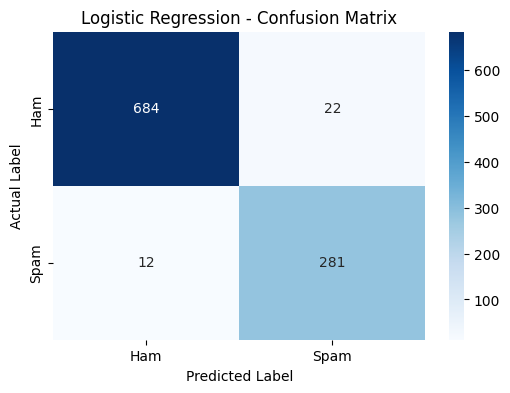

In [35]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Ham', 'Spam'],
    yticklabels=['Ham', 'Spam']
)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Logistic Regression - Confusion Matrix')
plt.show()

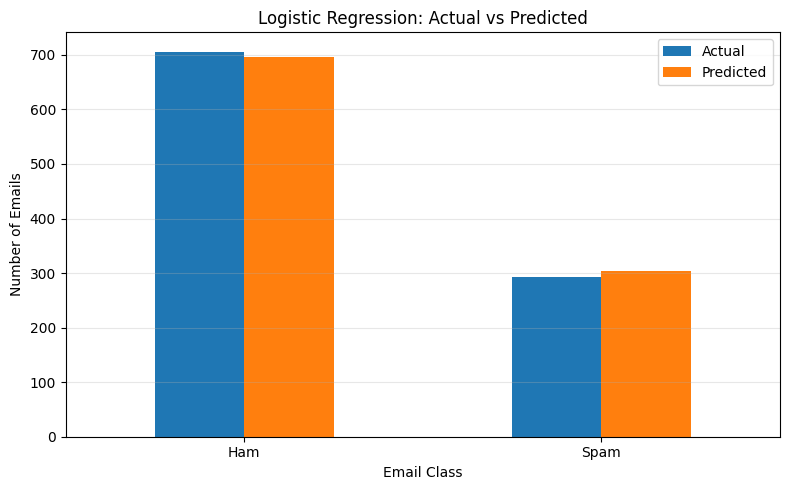

In [36]:
logistic_comparison = pd.DataFrame({
    'Actual': y_test.value_counts().sort_index(),
    'Predicted': pd.Series(y_pred).value_counts().sort_index()
})

logistic_comparison.index = ['Ham', 'Spam']

logistic_comparison.plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Logistic Regression: Actual vs Predicted')
plt.xlabel('Email Class')
plt.ylabel('Number of Emails')
plt.xticks(rotation=0)
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

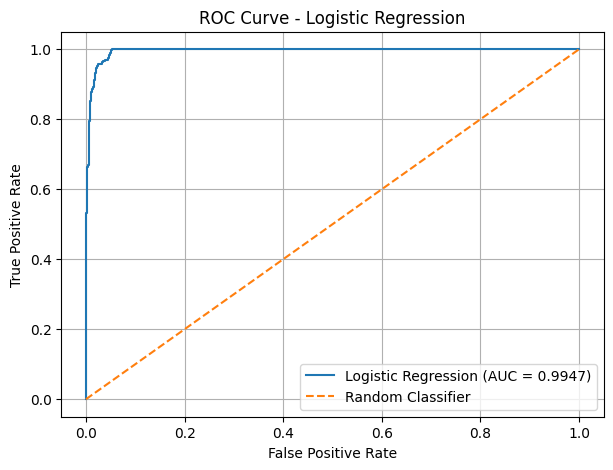

ROC-AUC Score: 0.9947016794129306


In [40]:
y_prob = lr_model.predict_proba(X_test_selected)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

roc_auc = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(7, 5))

plt.plot(fpr, tpr, label=f'Logistic Regression (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Logistic Regression')
plt.legend()
plt.grid()
plt.show()

print("ROC-AUC Score:", roc_auc)

# ***Balanced logistic regression***

In [42]:
lr_balanced = LogisticRegression(
    max_iter=1000,
    class_weight='balanced'
)

lr_balanced.fit(X_train_selected, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000)

In [43]:
y_pred_balanced = lr_balanced.predict(X_test_selected)

print("Balanced Predictions:", y_pred_balanced[:10])
print("Actual Values:", y_test[:10].values)

Balanced Predictions: [0 0 1 0 1 1 1 0 0 1]
Actual Values: [0 0 1 0 1 1 0 0 0 1]


In [44]:
accuracy_bal = accuracy_score(y_test, y_pred_balanced)
precision_bal = precision_score(y_test, y_pred_balanced)
recall_bal = recall_score(y_test, y_pred_balanced)
f1_bal = f1_score(y_test, y_pred_balanced)

print("Balanced Logistic Regression Evaluation:")
print("----------------------------------------")
print("Accuracy :", accuracy_bal)
print("Precision:", precision_bal)
print("Recall   :", recall_bal)
print("F1-score :", f1_bal)

Balanced Logistic Regression Evaluation:
----------------------------------------
Accuracy : 0.9519519519519519
Precision: 0.8592375366568915
Recall   : 1.0
F1-score : 0.9242902208201893


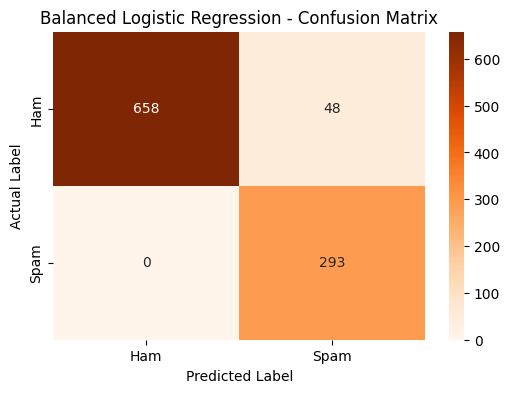

In [45]:
cm_balanced = confusion_matrix(y_test, y_pred_balanced)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_balanced,
    annot=True,
    fmt='d',
    cmap='Oranges',
    xticklabels=['Ham', 'Spam'],
    yticklabels=['Ham', 'Spam']
)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Balanced Logistic Regression - Confusion Matrix')
plt.show()

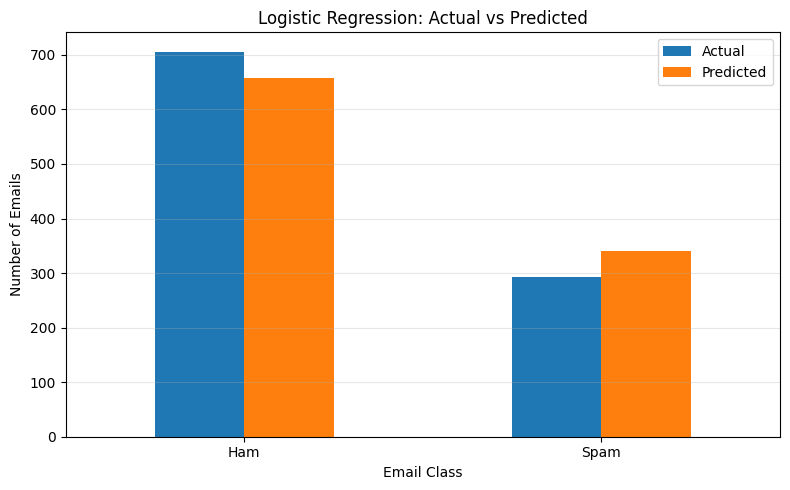

In [46]:
logistic_comparison = pd.DataFrame({
    'Actual': y_test.value_counts().sort_index(),
    'Predicted': pd.Series(y_pred_balanced).value_counts().sort_index()
})

logistic_comparison.index = ['Ham', 'Spam']

logistic_comparison.plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title(' Balanced Logistic Regression: Actual vs Predicted')
plt.xlabel('Email Class')
plt.ylabel('Number of Emails')
plt.xticks(rotation=0)
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# ***Naive Bayes***


In [50]:
from sklearn.naive_bayes import MultinomialNB

nb_model = MultinomialNB()

nb_model.fit(X_train_selected, y_train)

MultinomialNB()

In [51]:
y_pred_nb = nb_model.predict(X_test_selected)

print("Naive Bayes Predictions:", y_pred_nb[:10])
print("Actual Values:", y_test[:10].values)

Naive Bayes Predictions: [0 0 1 0 1 1 1 0 0 1]
Actual Values: [0 0 1 0 1 1 0 0 0 1]


In [53]:

accuracy_nb = accuracy_score(y_test, y_pred_nb)
precision_nb = precision_score(y_test, y_pred_nb)
recall_nb = recall_score(y_test, y_pred_nb)
f1_nb = f1_score(y_test, y_pred_nb)


y_prob_nb = nb_model.predict_proba(X_test_selected)[:, 1]
roc_auc_nb = roc_auc_score(y_test, y_prob_nb)

print("Multinomial Naive Bayes Evaluation:")
print("----------------------------------")
print("Accuracy :", accuracy_nb)
print("Precision:", precision_nb)
print("Recall   :", recall_nb)
print("F1-score :", f1_nb)
print("ROC-AUC  :", roc_auc_nb)

Multinomial Naive Bayes Evaluation:
----------------------------------
Accuracy : 0.9519519519519519
Precision: 0.881619937694704
Recall   : 0.9658703071672355
F1-score : 0.9218241042345277
ROC-AUC  : 0.9891519786520221


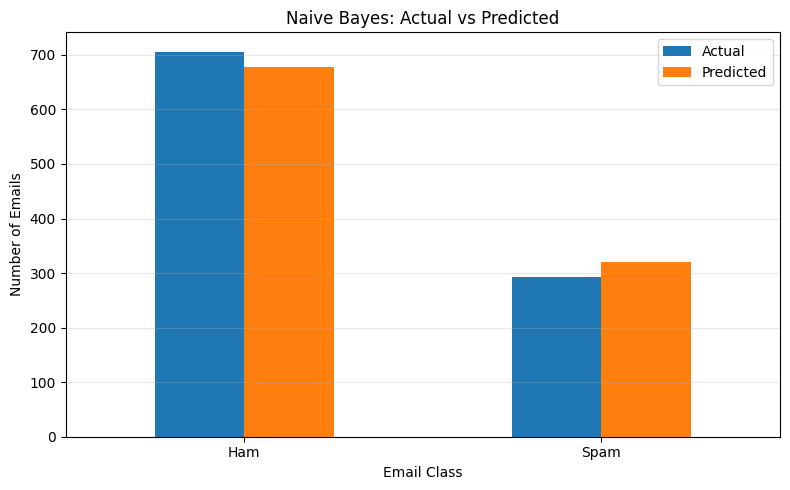

In [54]:
nb_comparison = pd.DataFrame({
    'Actual': y_test.value_counts().sort_index(),
    'Predicted': pd.Series(y_pred_nb).value_counts().sort_index()
})

nb_comparison.index = ['Ham', 'Spam']

nb_comparison.plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Naive Bayes: Actual vs Predicted')
plt.xlabel('Email Class')
plt.ylabel('Number of Emails')
plt.xticks(rotation=0)
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

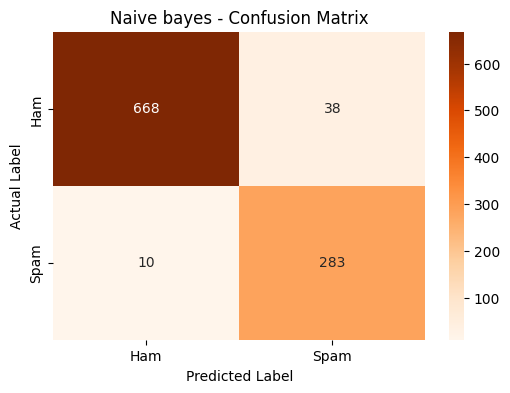

In [57]:
cm_balanced = confusion_matrix(y_test, y_pred_nb)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_balanced,
    annot=True,
    fmt='d',
    cmap='Oranges',
    xticklabels=['Ham', 'Spam'],
    yticklabels=['Ham', 'Spam']
)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Naive bayes - Confusion Matrix')
plt.show()

# ***comparison***


In [58]:
model_comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Balanced Logistic Regression',
        'Multinomial Naive Bayes'
    ],
    'Accuracy': [
        accuracy, accuracy_bal, accuracy_nb
    ],
    'Precision': [
        precision, precision_bal, precision_nb
    ],
    'Recall': [
        recall, recall_bal, recall_nb
    ],
    'F1-score': [
        f1, f1_bal, f1_nb
    ],

})

print(model_comparison.round(4))

                          Model  Accuracy  Precision  Recall  F1-score
0           Logistic Regression     0.966     0.9274  0.9590    0.9430
1  Balanced Logistic Regression     0.952     0.8592  1.0000    0.9243
2       Multinomial Naive Bayes     0.952     0.8816  0.9659    0.9218


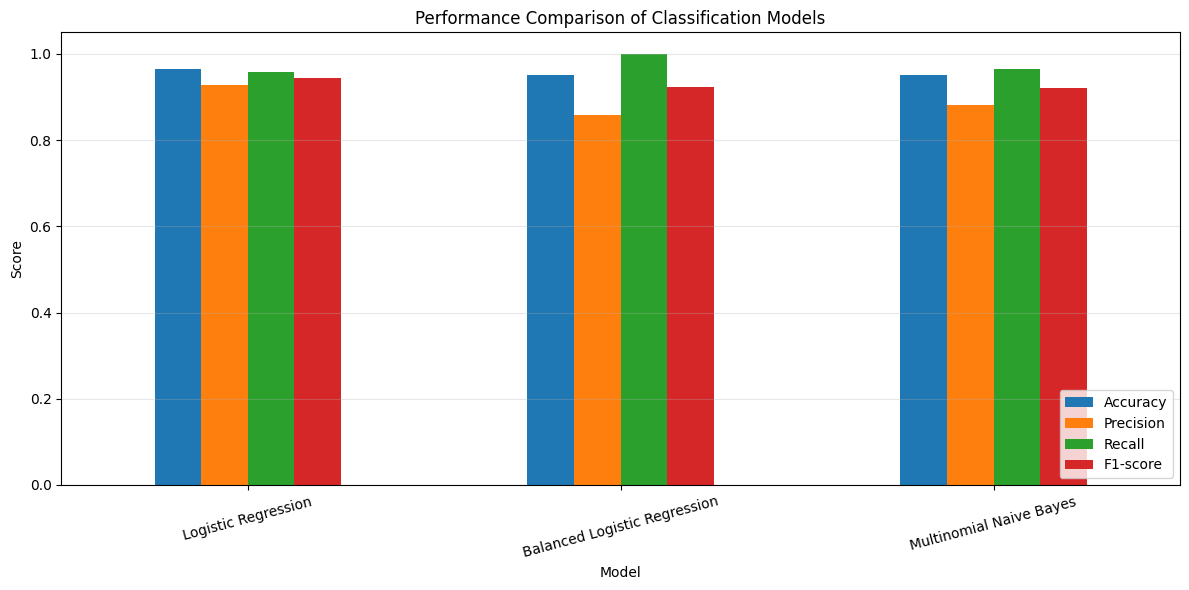

In [59]:
model_comparison.set_index('Model')[
    ['Accuracy', 'Precision', 'Recall', 'F1-score']
].plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Performance Comparison of Classification Models')
plt.ylabel('Score')
plt.ylim(0, 1.05)
plt.xticks(rotation=15)
plt.legend(loc='lower right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()